In [1]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt

HAM = "../data/online_retail_ii.csv"
MART = "../data/mart_musteri_rfm.parquet"
AYLIK = "../data/mart_aylik_satis.parquet"

con = duckdb.connect()
con.sql(f"""
create view ham as
select invoice, stock_code, description,
       try_cast(quantity as integer)       as quantity,
       try_cast(invoice_date as timestamp) as invoice_date,
       try_cast(unit_price as double)      as unit_price,
       try_cast(customer_id as double)     as customer_id,
       country
from read_csv('{HAM}', header=true, all_varchar=true)
""")
print("Hazir")

Hazir


In [2]:
con.sql("""
select count(*)                    as satir,
       count(distinct invoice)     as fatura,
       count(distinct customer_id) as musteri,
       count(distinct stock_code)  as urun,
       count(distinct country)     as ulke,
       min(invoice_date)           as ilk_tarih,
       max(invoice_date)           as son_tarih
from ham
""").df().T

,0
satir,1067371
fatura,53628
musteri,5942
urun,5305
ulke,43
ilk_tarih,2009-12-01 07:45:00
son_tarih,2011-12-09 12:50:00


In [3]:
con.sql("""
select
    count(*)                                                as toplam_satir,
    sum(case when customer_id is null then 1 else 0 end)   as musterisi_bos,
    sum(case when invoice like 'C%' then 1 else 0 end)     as iptal_fatura,
    sum(case when quantity <= 0 then 1 else 0 end)         as adet_sifir_veya_eksi,
    sum(case when unit_price <= 0 then 1 else 0 end)       as fiyat_sifir_veya_eksi
from ham
""").df().T

,0
toplam_satir,1067371.0
musterisi_bos,243007.0
iptal_fatura,19494.0
adet_sifir_veya_eksi,22950.0
fiyat_sifir_veya_eksi,6207.0


## Veri kalitesi
Ham veride 1.067.371 satır var. Müşteri numarası boş olan satırlar 243.007 (%22,8), iptal faturası satırları 19.494, adedi sıfır ya da eksi olan satırlar 22.950, fiyatı sıfır ya da eksi olan satırlar 6.207. Müşteri numarası olmayan satırlar müşteri analizine giremez; iptal ve hatalı adet/fiyat satırları da gerçek satış sayılmaz. Bu yüzden dbt staging katmanında (stg_satis) bu satırlar çıkarılıyor ve 805.549 satır kalıyor.

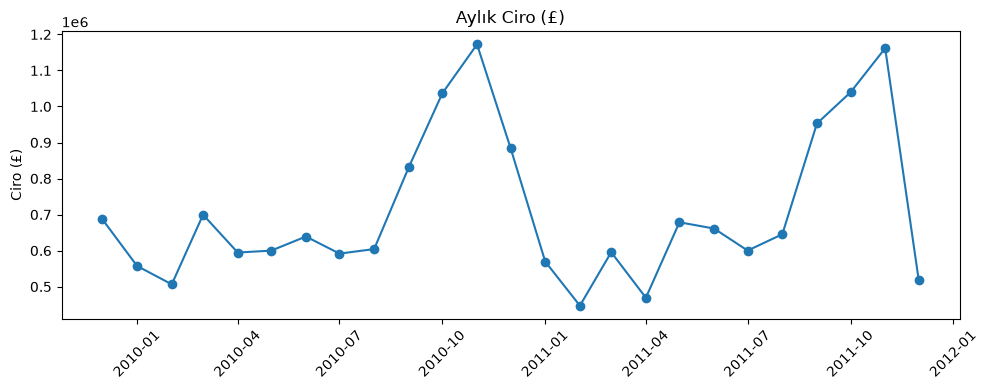

In [4]:
aylik = con.sql(f"select * from read_parquet('{AYLIK}') order by ay").df()

plt.figure(figsize=(10, 4))
plt.plot(aylik["ay"], aylik["ciro"], marker="o")
plt.title("Aylık Ciro (£)")
plt.ylabel("Ciro (£)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Aylık ciro
Ciro hem 2010 hem 2011 Kasım ayında en yüksek seviyeye çıkıyor; bunun olası açıklaması yılsonu hediye sezonu öncesi yapılan alımlar. 2011'de Şubat ve Nisan en düşük aylar. Veri 9 Aralık 2011'de bittiği için Aralık 2011 eksik bir ay; grafiğin sonundaki düşüş gerçek bir düşüş değil.

          ulke       ciro
United Kingdom 14723148.0
          EIRE   621631.0
   Netherlands   554232.0
       Germany   431262.0
        France   355257.0
     Australia   169968.0
         Spain   109179.0
   Switzerland   100365.0
        Sweden    91550.0
       Denmark    69862.0


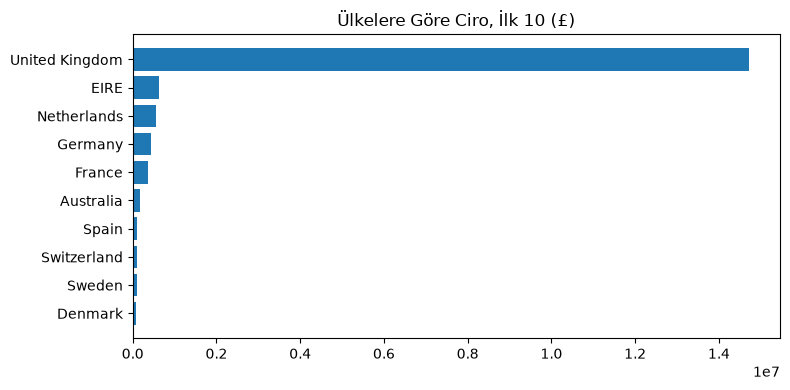

In [5]:
ulke = con.sql("""
select country as ulke, round(sum(quantity * unit_price), 0) as ciro
from ham
where customer_id is not null and invoice not like 'C%'
  and quantity > 0 and unit_price > 0
group by 1
order by ciro desc
limit 10
""").df()

print(ulke.to_string(index=False))

ulke = ulke.sort_values("ciro")
plt.figure(figsize=(8, 4))
plt.barh(ulke["ulke"], ulke["ciro"])
plt.title("Ülkelere Göre Ciro, İlk 10 (£)")
plt.tight_layout()
plt.show()

## Ülkelere göre ciro
Ciro büyük ölçüde Birleşik Krallık'ta toplanıyor: ilk 10 ülkenin toplam cirosunun yaklaşık %85'i tek başına United Kingdom'dan geliyor (14,7 milyon £). İkinci sıradaki İrlanda (EIRE) yalnızca 0,62 milyon £ ile UK'nin yaklaşık 24'te biri kadar; Hollanda, Almanya ve Fransa onu izliyor. Bu yüzden analiz ağırlıklı olarak Birleşik Krallık müşterilerini yansıtıyor; küçük ülkeler büyük ihtimalle az sayıda müşteriye dayandığı için ülke karşılaştırmalarında dikkatli olmak gerekir.

fatura_sayisi  musteri
            1     1576
            2      897
            3      578
            4      428
            5      316
            6      238
            7      193
            8      149
            9      133
          10+      773


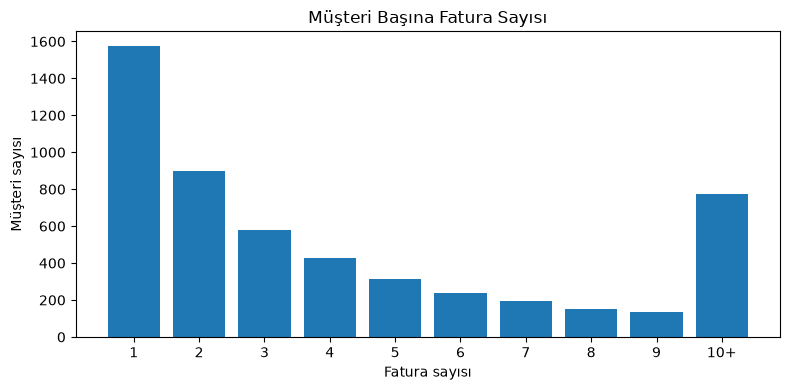

In [6]:
sik = con.sql(f"""
select case when frequency >= 10 then '10+' else cast(frequency as varchar) end as fatura_sayisi,
       count(*) as musteri
from read_parquet('{MART}')
group by 1
order by min(frequency)
""").df()

print(sik.to_string(index=False))

plt.figure(figsize=(8, 4))
plt.bar(sik["fatura_sayisi"], sik["musteri"])
plt.title("Müşteri Başına Fatura Sayısı")
plt.xlabel("Fatura sayısı")
plt.ylabel("Müşteri sayısı")
plt.tight_layout()
plt.show()

## Müşteri başına fatura sayısı
Kesme tarihine (9 Eylül 2011) kadar alışveriş yapmış 5.281 müşteriden 1.576'sı (%29,8) yalnızca bir kez alışveriş yapmış, 2.473'ü (%46,8) en fazla iki kez. Buna karşılık 773 müşteri (%14,6) 10 veya daha fazla alışveriş yapmış. Dağılım sağa çarpık: az sayıda sadık müşteri çok sık alışveriş yapıyor, geniş bir kitle ise bir iki kez gelip kayboluyor. Bu yapı, RFM segmentasyonunun ve churn analizinin neden anlamlı olduğunu gösteriyor; elde tutma çabası özellikle ilk alışverişten sonra geri dönmeyen müşterilere odaklanabilir.

## Sonuç
- Veri kalitesi sorunları (boş müşteri numarası, iptal, hatalı adet/fiyat) dbt staging katmanında temizlendi.
- Satışlar yılsonu sezonunda (Kasım) zirve yapıyor ve Birleşik Krallık'ta yoğunlaşıyor.
- Müşterilerin büyük kısmı az sayıda alışveriş yapıyor; bu durum RFM segmentasyonunu ve 90 günlük churn tanımını destekliyor.